# PCA on the Iris dataset: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/decomposition/plot_pca_iris.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/decomposition/plot_pca_iris.html)).

**Scenario:** the bundled Iris data (150 x 4) projected onto its first three principal components with
`PCA(n_components=3).fit_transform(iris.data)`, drawn as a 3-D scatter.

**Adaptations:**
- The seaborn pair plot of the raw features is plotting-only and is skipped (seaborn is not in the environment);
  `load_iris(as_frame=True)` is replaced by the NumPy arrays (pandas input is excluded Moxie-wide).
- The example uses only the default solver. To exercise the rest of the PCA surface on the same data the
  notebook adds, as extra checks, every `svd_solver` (`full`, `arpack`, `covariance_eigh`, `randomized`),
  `whiten=True` with `inverse_transform`, fractional (`0.95`) and `"mle"` component counts, the probabilistic
  model (`get_covariance`, `get_precision`, `score_samples`, `score`), `get_feature_names_out` and a Float32 fit.
- Labels stay on the Python side; they are only used to colour the plot.

**Determinism:** deterministic. `full`/`arpack`/`covariance_eigh` are deterministic factorizations; the
randomized solver is fixed with `random_state=0` and Moxie reproduces NumPy's legacy integer-seeded normal
stream, so all quantities are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("decomposition/plot_pca_iris")

## 1. scikit-learn (Python reference)

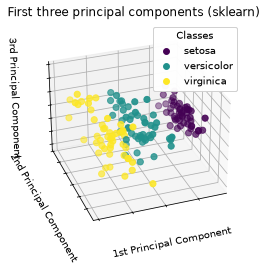

explained_variance_ratio_: [0.92461872 0.05306648 0.01710261]
0.95 -> 2 components; mle -> 3 components; Float32 output float32


In [2]:
import matplotlib.pyplot as plt
import mpl_toolkits.mplot3d  # noqa: F401
import numpy as np

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()
X = iris.data

fig = plt.figure(1, figsize=(5, 4), dpi=70)
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)
sk_pca = PCA(n_components=3)
X_reduced = sk_pca.fit_transform(X)
scatter = ax.scatter(X_reduced[:, 0], X_reduced[:, 1], X_reduced[:, 2], c=iris.target, s=40)
ax.set(title="First three principal components (sklearn)", xlabel="1st Principal Component",
       ylabel="2nd Principal Component", zlabel="3rd Principal Component")
ax.xaxis.set_ticklabels([]); ax.yaxis.set_ticklabels([]); ax.zaxis.set_ticklabels([])
ax.add_artist(ax.legend(scatter.legend_elements()[0], iris.target_names.tolist(), loc="upper right", title="Classes"))
plt.show()

# Extra checks on the same data (not part of the gallery script).
sk = {}
for solver in ["full", "arpack", "covariance_eigh", "randomized"]:
    m = PCA(n_components=3, svd_solver=solver, random_state=0)
    sk[f"{solver}_scores"] = m.fit_transform(X)
    sk[f"{solver}_components"] = m.components_
    sk[f"{solver}_singular"] = m.singular_values_
w = PCA(n_components=2, whiten=True).fit(X)
sk["whiten_scores"] = w.transform(X)
sk["whiten_inverse"] = w.inverse_transform(w.transform(X))
frac = PCA(n_components=0.95).fit(X)
mle = PCA(n_components="mle").fit(X)
sk["frac_n"] = frac.n_components_
sk["mle_n"] = mle.n_components_
sk["mle_noise"] = mle.noise_variance_
sk["covariance"] = sk_pca.get_covariance()
sk["precision"] = sk_pca.get_precision()
sk["score_samples"] = sk_pca.score_samples(X)
sk["score"] = sk_pca.score(X)
sk["names"] = sk_pca.get_feature_names_out()
X32 = X.astype(np.float32)
p32 = PCA(n_components=3).fit(X32)
sk["f32_scores"] = p32.transform(X32)
sk["f32_dtype"] = p32.transform(X32).dtype
print("explained_variance_ratio_:", sk_pca.explained_variance_ratio_)
print("0.95 ->", sk["frac_n"], "components; mle ->", sk["mle_n"], "components; Float32 output", sk["f32_dtype"])
nb.share(X=X, X32=X32)

## 2. Moxie (native Mojo)

The same scenario through `moxie.decomposition.PCA`; Python only supplies the data files.

In [3]:
%%mojo pca_iris
from moxie.decomposition import PCA
from moxie_nb_io import load, save, save_floats, save_ints, save_strings


def main() raises:
    var X = load("X")
    var pca = PCA(n_components=3)
    var X_reduced = pca.fit_transform(X)
    save("X_reduced", X_reduced)
    save("components", pca.components_.value())
    save("explained_variance", pca.explained_variance_.value())
    save("explained_variance_ratio", pca.explained_variance_ratio_.value())
    save("singular_values", pca.singular_values_.value())
    save("mean", pca.mean_.value())
    save_floats("noise_variance", [pca.noise_variance_])
    save("covariance", pca.get_covariance())
    save("precision", pca.get_precision())
    save("score_samples", pca.score_samples(X))
    save_floats("score", [pca.score(X)])
    save_strings("names", pca.get_feature_names_out())
    print("explained_variance_ratio_:", pca.explained_variance_ratio_.value())

    for solver in ["full", "arpack", "covariance_eigh", "randomized"]:
        var m = PCA(n_components=3, svd_solver=solver, random_state=0)
        save(solver + "_scores", m.fit_transform(X))
        save(solver + "_components", m.components_.value())
        save(solver + "_singular", m.singular_values_.value())

    var w = PCA(n_components=2, whiten=True)
    _ = w.fit(X)
    var z = w.transform(X)
    save("whiten_scores", z)
    save("whiten_inverse", w.inverse_transform(z))

    var frac = PCA(n_components=Float64(0.95))
    _ = frac.fit(X)
    var mle = PCA(n_components="mle")
    _ = mle.fit(X)
    save_ints("ranks", [frac.n_components_, mle.n_components_])
    save_floats("mle_noise", [mle.noise_variance_])

    var X32 = load[DType.float32]("X32")
    var p32 = PCA[DType.float32](n_components=3)
    _ = p32.fit(X32)
    save("f32_scores", p32.transform(X32))
    print("0.95 ->", frac.n_components_, "components; mle ->", mle.n_components_, "components")

explained_variance_ratio_: [0.9246 0.0531 0.0171]
1D-array  Shape: (3)  Strides: (1)  DType: f64  order: C  own data: True
0.95 -> 2 components; mle -> 3 components


## 3. Side by side and parity

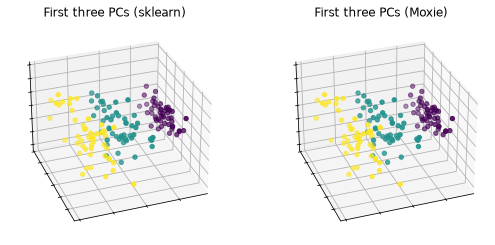

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
fit_transform (X_reduced),PASS,"(150, 3)","(150, 3)",1.42e-14,1.17e-12,"rtol=1e-09, atol=1e-11",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only; same svd_flip sign rule
components_,PASS,"(3, 4)","(3, 4)",1.51e-14,1.19e-13,"rtol=1e-09, atol=1e-11",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only
explained_variance_,PASS,"(3,)","(3,)",2.66e-14,2.79e-14,"rtol=1e-11, atol=0",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only
explained_variance_ratio_,PASS,"(3,)","(3,)",1.09e-15,2.05e-14,"rtol=1e-11, atol=0",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only
singular_values_,PASS,"(3,)","(3,)",8.35e-14,1.39e-14,"rtol=1e-11, atol=0",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only
mean_,PASS,"(4,)","(4,)",2.22e-15,5.91e-16,"rtol=1e-13, atol=0",,150-term column means; summation order only
noise_variance_,PASS,(),(),3.19e-16,1.34e-14,"rtol=1e-09, atol=0",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only
get_covariance(),PASS,"(4, 4)","(4, 4)",1.42e-14,1.49e-13,"rtol=1e-09, atol=1e-12",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only
get_precision(),PASS,"(4, 4)","(4, 4)",4.6e-13,7.41e-14,"rtol=1e-08, atol=1e-10",,inverse of the covariance (condition ~ 4.2/0.024); rounding amplified by the condition number
score_samples(),PASS,"(150,)","(150,)",2.5e-13,4.13e-14,"rtol=1e-11, atol=0",,Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only; logs through the platform libm as in NumPy


In [4]:
mx = nb.results["pca_iris"]
moxie_nb.side_by_side(sklearn=X_reduced[:5], moxie=mx["X_reduced"][:5])
fig = plt.figure(figsize=(9, 4), dpi=70)
for k, (title, data) in enumerate([("sklearn", X_reduced), ("Moxie", mx["X_reduced"])], 1):
    ax = fig.add_subplot(1, 2, k, projection="3d", elev=-150, azim=110)
    ax.scatter(data[:, 0], data[:, 1], data[:, 2], c=iris.target, s=20)
    ax.set_title(f"First three PCs ({title})")
    ax.xaxis.set_ticklabels([]); ax.yaxis.set_ticklabels([]); ax.zaxis.set_ticklabels([])
plt.show()

F64 = "Float64 Jacobi SVD (Moxie) vs LAPACK gesdd (sklearn) on a well-conditioned 150x4 matrix; rounding only"
nb.compare("fit_transform (X_reduced)", X_reduced, mx["X_reduced"], rtol=1e-9, atol=1e-11, reason=F64 + "; same svd_flip sign rule")
nb.compare("components_", sk_pca.components_, mx["components"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("explained_variance_", sk_pca.explained_variance_, mx["explained_variance"], rtol=1e-11, reason=F64)
nb.compare("explained_variance_ratio_", sk_pca.explained_variance_ratio_, mx["explained_variance_ratio"], rtol=1e-11, reason=F64)
nb.compare("singular_values_", sk_pca.singular_values_, mx["singular_values"], rtol=1e-11, reason=F64)
nb.compare("mean_", sk_pca.mean_, mx["mean"], rtol=1e-13, reason="150-term column means; summation order only")
nb.compare("noise_variance_", sk_pca.noise_variance_, mx["noise_variance"][0], rtol=1e-9, reason=F64)
nb.compare("get_covariance()", sk["covariance"], mx["covariance"], rtol=1e-9, atol=1e-12, reason=F64)
nb.compare("get_precision()", sk["precision"], mx["precision"], rtol=1e-8, atol=1e-10,
           reason="inverse of the covariance (condition ~ 4.2/0.024); rounding amplified by the condition number")
nb.compare("score_samples()", sk["score_samples"], mx["score_samples"], rtol=1e-11, reason=F64 + "; logs through the platform libm as in NumPy")
nb.compare("score()", sk["score"], mx["score"][0], rtol=1e-10, reason=F64)
nb.compare("get_feature_names_out()", sk["names"], mx["names"], exact=True)
for solver in ["full", "arpack", "covariance_eigh", "randomized"]:
    tol = dict(rtol=1e-7, atol=1e-8) if solver == "covariance_eigh" else dict(rtol=1e-9, atol=1e-10)
    why = ("eigendecomposition of X^T X squares the condition number; singular values are square roots of rounded eigenvalues"
           if solver == "covariance_eigh" else
           "same integer-seeded Gaussian sketch, 7 power iterations, LU normalizer; QR/SVD rounding only" if solver == "randomized"
           else "dense exact leading triplets vs ARPACK svds converged to machine precision" if solver == "arpack" else F64)
    nb.compare(f"svd_solver={solver!r} scores", sk[f"{solver}_scores"], mx[f"{solver}_scores"], reason=why, **tol)
    nb.compare(f"svd_solver={solver!r} components_", sk[f"{solver}_components"], mx[f"{solver}_components"], reason=why, **tol)
    nb.compare(f"svd_solver={solver!r} singular_values_", sk[f"{solver}_singular"], mx[f"{solver}_singular"], reason=why, **tol)
nb.compare("whiten=True transform", sk["whiten_scores"], mx["whiten_scores"], rtol=1e-9, atol=1e-11, reason=F64 + "; divided by sqrt(explained_variance_)")
nb.compare("whiten=True inverse_transform", sk["whiten_inverse"], mx["whiten_inverse"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("n_components=0.95 -> n_components_", sk["frac_n"], mx["ranks"][0], exact=True)
nb.compare("n_components='mle' -> n_components_", sk["mle_n"], mx["ranks"][1], exact=True)
nb.compare("'mle' noise_variance_", sk["mle_noise"], mx["mle_noise"][0], rtol=1e-9, reason=F64)
nb.compare("Float32 transform", sk["f32_scores"], mx["f32_scores"], rtol=1e-4, atol=1e-4,
           reason="Float32 throughout in both, with different reduction orders: sklearn's own Float32 scores "
                  "deviate from its Float64 scores by up to 6e-5 on this data (Moxie's by 2e-5), so two "
                  "correct Float32 runs can differ by ~1e-4")
nb.compare("Float32 transform vs Float64 reference", X_reduced, mx["f32_scores"].astype(float), rtol=1e-4, atol=1e-4,
           reason="Moxie's Float32 result is at least as close to the Float64 answer as sklearn's Float32 result (6e-5)")
nb.compare("Float32 output dtype", str(sk["f32_dtype"]), str(mx["f32_scores"].dtype), exact=True)
nb.note("seaborn pair plot", "SKIP", "plotting-only; seaborn is not installed in the notebook environment")
nb.note("load_iris(as_frame=True)", "ADAPTED", "pandas input/output is excluded Moxie-wide; NumPy arrays are shared instead")
nb.report()
nb.assert_parity()